# Multimodal Xenium (gene + protein) with MuData tables in SpatialData

This notebook reads a **Xenium In Situ Gene and Protein Expression** run into a `SpatialData` object whose table is a
[`MuData`](https://mudata.scverse.org) object, with one modality per assay (`"rna"`, `"prot"`), and analyses both
modalities natively: QC and normalization per modality, clustering, gene vs protein comparison, spatial plots of both
modalities, spatial queries and saving to disk.

It uses the experimental MuData support developed on the `claude/mudata-support-sdata-c2tfjf` branches of
`spatialdata`, `spatialdata-io` and `spatialdata-plot`, installed by the environment of this repository (see the
README: `uv sync`, then select the `.venv` kernel).

**Data**: the public 10x Genomics *Xenium V1 Protein Human Kidney tiny* dataset (21 MB): 358 cells, a 405-gene panel and
4 immune checkpoint proteins (PD-1, VISTA, PD-L1, LAG-3).

## 1. Check the environment

The environment of this repository (`uv sync`) installs the three packages from their development branches. The cell below shows the versions and checks that SpatialData accepts MuData tables.

In [1]:
import importlib.metadata

import anndata as ad
import mudata as md
import numpy as np
from spatialdata.models import TableModel

for package in [
    "spatialdata",
    "spatialdata-io",
    "spatialdata-plot",
    "mudata",
    "anndata",
    "scanpy",
    "muon",
]:
    print(f"{package:>16}: {importlib.metadata.version(package)}")

# fails with a TypeError on SpatialData versions without MuData tables
TableModel.validate(md.MuData({"rna": ad.AnnData(np.ones((1, 1)))}))

     spatialdata: 0.8.1.dev44+g135ac4842
  spatialdata-io: 0.1.dev1195+g523292142
spatialdata-plot: 0.4.4.dev2+g8f1637bea
          mudata: 0.4.1
         anndata: 0.13.4
          scanpy: 1.12.4
            muon: 0.2.0


MuData object with n_obs × n_vars = 1 × 1
  1 modality
    rna:	1 × 1
      layers:	None

In [2]:
import warnings
import zipfile
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import mudata as md
import muon as mu
import numpy as np
import pandas as pd
import scanpy as sc
import spatialdata as sd
import spatialdata_plot  # noqa: F401
from scipy.stats import spearmanr
from spatialdata_io import xenium

warnings.filterwarnings("ignore", category=FutureWarning)
sc.settings.verbosity = 0

## 2. Download the dataset

In [3]:
DATA = Path("data")
DATASET = "Xenium_V1_Protein_Human_Kidney_tiny"
url = f"https://cf.10xgenomics.com/samples/xenium/4.0.0/{DATASET}/{DATASET}_outs.zip"
bundle = DATA / f"{DATASET}_outs"
if not bundle.exists():
    DATA.mkdir(exist_ok=True)
    archive, _ = urlretrieve(url, DATA / f"{DATASET}_outs.zip")
    with zipfile.ZipFile(archive) as z:
        z.extractall(bundle)
sorted(p.name for p in bundle.iterdir())

['.end-of-run',
 'analysis.tar.gz',
 'analysis.zarr.zip',
 'analysis_summary.html',
 'aux_outputs.tar.gz',
 'cell_boundaries.csv.gz',
 'cell_boundaries.parquet',
 'cell_feature_matrix.h5',
 'cell_feature_matrix.tar.gz',
 'cell_feature_matrix.zarr.zip',
 'cells.csv.gz',
 'cells.parquet',
 'cells.zarr.zip',
 'experiment.xenium',
 'gene_panel.json',
 'metrics_summary.csv',
 'morphology.ome.tif',
 'morphology_focus',
 'nucleus_boundaries.csv.gz',
 'nucleus_boundaries.parquet',
 'protein_panel.json',
 'transcripts.parquet',
 'transcripts.zarr.zip']

## 3. Read it as SpatialData with a MuData table

`multimodal=True` splits the cell feature matrix by assay: the protein features (descaled from Xenium's fixed-point
encoding) go to the `"prot"` modality and the gene expression features to `"rna"`, following muon's naming. The cell
annotations, the centroids (`obsm["spatial"]`) and the link to the spatial elements are **global**, so both modalities
annotate the same cells of the `cell_labels` element.

In [4]:
sdata = xenium(bundle, multimodal=True)
sdata

SpatialData object
├── Images
│     └── 'morphology_focus': DataTree[cyx] (12, 6915, 2963), (12, 3457, 1481), (12, 1728, 740), (12, 864, 370), (12, 432, 185)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (6915, 2963), (3457, 1481), (1728, 740), (864, 370), (432, 185)
│     └── 'nucleus_labels': DataTree[yx] (6915, 2963), (3457, 1481), (1728, 740), (864, 370), (432, 185)
├── Points
│     └── 'transcripts': DataFrame with shape: (26463, 13) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (358, 1) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (368, 2) (2D shapes)
└── Tables
      └── 'table': MuData (358, 409)
with coordinate systems:
    ▸ 'global', with elements:
        morphology_focus (Images), cell_labels (Labels), nucleus_labels (Labels), transcripts (Points), cell_boundaries (Shapes), nucleus_boundaries (Shapes)

In [5]:
mdata = sdata["table"]
mdata

MuData object with n_obs × n_vars = 358 × 409
  obs:	'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels'
  uns:	'spatialdata_attrs'
  obsm:	'spatial'
  2 modalities
    rna:	358 × 405
      var:	'gene_ids', 'feature_types', 'genome'
      layers:	None
    prot:	358 × 4
      var:	'gene_ids', 'feature_types', 'genome'
      layers:	None

In [6]:
# the table annotates the cell segmentation mask: instance ids are the label values
mdata.uns["spatialdata_attrs"]

{'region': 'cell_labels',
 'region_key': 'region',
 'instance_key': 'cell_labels'}

## 4. Quality control

Cells with fewer than 10 transcripts are removed (a common threshold for Xenium data; here it removes the lowest ~7% of
cells). Filtering on the global `obs` removes the cells from all the modalities at once.

In [7]:
print("transcripts per cell, quantiles 0/5/25/50/75/95/100%:")
print(np.percentile(mdata.obs["transcript_counts"], [0, 5, 25, 50, 75, 95, 100]))
mu.pp.filter_obs(mdata, "transcript_counts", lambda x: x >= 10)
print(mdata.shape, {name: m.shape for name, m in mdata.mod.items()})

transcripts per cell, quantiles 0/5/25/50/75/95/100%:
[  0.     8.    25.    41.    63.75 114.15 200.  ]
(334, 409) {'rna': (334, 405), 'prot': (334, 4)}


## 5. RNA: normalization and clustering

Standard processing: total-count normalization, `log1p`, PCA, k-nearest-neighbor graph and Leiden clustering. With a
405-gene panel, all genes are used.

In [8]:
rna = mdata.mod["rna"]
rna.layers["counts"] = rna.X.copy()
sc.pp.normalize_total(rna)
sc.pp.log1p(rna)
sc.tl.pca(rna, n_comps=20)
sc.pp.neighbors(rna, use_rep="X_pca")
sc.tl.umap(rna)
sc.tl.leiden(rna, resolution=0.5, key_added="leiden", flavor="igraph", n_iterations=2)
rna.obs["leiden"].value_counts().sort_index()

leiden
0    140
1     30
2     50
3     75
4     39
Name: count, dtype: int64

In [9]:
sc.tl.rank_genes_groups(rna, "leiden", method="wilcoxon")
markers = pd.DataFrame(rna.uns["rank_genes_groups"]["names"]).head(5)
markers

,0,1,2,3,4
0,MS4A1,PTPRC,MS4A6A,PECAM1,TNC
1,CXCR4,CD3D,CD68,APOLD1,VCAN
2,HLA-DRA,CD3E,HLA-DRB1,VWF,CRISPLD2
3,BANK1,TRAC,VCAN,EGFL7,FBN1
4,CD79A,IL7R,AIF1,TFPI,LIF


The clusters are annotated with canonical marker genes: each cluster gets the cell type whose markers have the highest
mean expression in it (cluster means z-scored across clusters, so that highly expressed genes do not dominate).

In [10]:
marker_genes = {
    "B cells": ["MS4A1", "CD79A", "BANK1"],
    "T cells": ["CD3D", "CD3E", "TRAC"],
    "myeloid": ["CD68", "AIF1", "MS4A6A"],
    "endothelial": ["PECAM1", "VWF", "EGFL7"],
    "stromal": ["VCAN", "FBN1", "TNC"],
}
cluster_means = rna.to_df().groupby(rna.obs["leiden"], observed=True).mean()
cluster_means = (cluster_means - cluster_means.mean()) / cluster_means.std()
scores = pd.DataFrame({cell_type: cluster_means[genes].mean(axis=1) for cell_type, genes in marker_genes.items()})
annotation = scores.idxmax(axis=1)
rna.obs["cell_type"] = pd.Categorical(rna.obs["leiden"].map(annotation).astype(str))
scores.round(2).assign(cell_type=annotation)

,B cells,T cells,myeloid,endothelial,stromal,cell_type
leiden,,,,,,
0,1.77,-0.43,-0.80,-0.69,-0.65,B cells
1,-0.26,1.77,-0.19,-0.44,-0.44,T cells
2,-0.49,-0.34,1.69,-0.41,0.22,myeloid
3,-0.53,-0.54,-0.57,1.74,-0.52,endothelial
4,-0.49,-0.47,-0.14,-0.20,1.40,stromal


## 6. Protein: normalization

Xenium protein values are per-cell mean fluorescence intensities: non-negative, zero-inflated and long-tailed. They
are `log1p`-transformed (for these ranges, close to the arcsinh transform used for cytometry data); the raw
intensities are kept in a layer. CLR, used for CITE-seq antibody counts, is not used for intensities.

In [11]:
prot = mdata.mod["prot"]
prot.layers["intensity"] = prot.X.copy()
prot.X = np.log1p(prot.X.toarray())

intensity = prot.layers["intensity"].toarray()
pd.DataFrame(
    {
        "fraction of cells > 0": (intensity > 0).mean(axis=0),
        "median": np.median(intensity, axis=0),
        "99th percentile": np.percentile(intensity, 99, axis=0),
    },
    index=prot.var_names,
).round(2)

,fraction of cells > 0,median,99th percentile
PD-1,0.09,0.0,13.040000
VISTA,0.51,0.1,30.139999
PD-L1,0.04,0.0,1.600000
LAG-3,0.08,0.0,9.110000


### Joint RNA + protein clustering (weighted nearest neighbors)

muon's weighted nearest neighbors (WNN, `muon.pp.neighbors`) combines the RNA and protein neighbor graphs, weighting each
modality per cell by how well it predicts that cell's neighborhood. In this small crop, many cells have **no** signal
for any of the 4 proteins, so they share an identical protein profile and their protein neighbors are all at distance
0. The cell below quantifies this.

In [12]:
no_protein_signal = (intensity == 0).all(axis=1)
print(
    f"cells without signal for any of the {prot.n_vars} proteins: {no_protein_signal.sum()} of {prot.n_obs} "
    f"({no_protein_signal.mean():.0%})"
)

cells without signal for any of the 4 proteins: 148 of 334 (44%)


muon 0.2.0 does not handle such ties: it averages the profiles of a cell's neighbors found with
`distances[cell].nonzero()`, which drops the neighbors at distance exactly 0 (all of them, for these cells), and their
kernel bandwidth is 0, so WNN returns NaN for these cells. The cell below patches `muon.pp.neighbors` in place with two
changes: the neighbors are taken from the structure of the graph (all stored neighbors, including those at distance 0),
and the bandwidth is kept above the distance to the nearest neighbor by muon's own `eps`. Cells with a protein signal are
unaffected. The patch checks that it applies to the installed muon version and fails otherwise; the bug is worth
reporting upstream.

In [13]:
import inspect
import textwrap

import muon.pp

source = textwrap.dedent(inspect.getsource(muon.pp.neighbors))
fixes = {
    # include the neighbors at distance 0 (identical profiles), which `.nonzero()` drops
    "X[neighbordistances[cell, :].nonzero()[1], :]": (
        "X[neighbordistances.indices[neighbordistances.indptr[cell] : neighbordistances.indptr[cell + 1]], :]"
    ),
    # keep the kernel bandwidth above the nearest-neighbor distance, which is 0 for identical profiles
    "        currtheta = 0\n": "        csigmas = np.maximum(csigmas, nndistances + eps)\n        currtheta = 0\n",
}
for old, new in fixes.items():
    assert source.count(old) == 1, f"the patch does not apply to muon {importlib.metadata.version('muon')}"
    source = source.replace(old, new)
exec(compile(source, muon.pp.__file__, "exec"), muon.pp.__dict__)

With the patch, the protein graph is built on the 4 log-transformed markers (no PCA for 4 features), and the joint
graph is clustered with Leiden. The modality weights show how WNN treats the two groups of cells: it relies on RNA for
the cells without protein signal and leans on protein for the others.

In [14]:
sc.pp.neighbors(prot, use_rep="X")
mu.pp.neighbors(mdata, key_added="wnn")
mu.tl.umap(mdata, neighbors_key="wnn")
sc.tl.leiden(mdata, neighbors_key="wnn", key_added="leiden_wnn", resolution=0.5, flavor="igraph", n_iterations=2)

weights = mdata.obs[["rna:mod_weight", "prot:mod_weight"]]
weights.groupby(
    pd.Series(np.where(no_protein_signal, "no protein signal", "protein signal"), index=weights.index)
).mean().round(2)

,rna:mod_weight,prot:mod_weight
no protein signal,0.61,0.39
protein signal,0.30,0.70


In [15]:
from sklearn.metrics import adjusted_rand_score

print(f"agreement with the RNA clusters (ARI): {adjusted_rand_score(rna.obs['leiden'], mdata.obs['leiden_wnn']):.2f}")
print(
    f"agreement with 'any protein signal' (ARI): {adjusted_rand_score(no_protein_signal, mdata.obs['leiden_wnn']):.2f}"
)
pd.crosstab(mdata.obs["leiden_wnn"], rna.obs["cell_type"]).assign(
    **{
        "without protein signal": pd.Series(no_protein_signal, index=mdata.obs_names)
        .groupby(mdata.obs["leiden_wnn"])
        .sum()
    }
)

agreement with the RNA clusters (ARI): 0.37
agreement with 'any protein signal' (ARI): 0.32


cell_type,B cells,T cells,endothelial,myeloid,stromal,without protein signal
leiden_wnn,,,,,,
0,14,5,0,1,1,0
1,14,10,20,4,4,1
2,5,8,19,15,9,0
3,0,0,11,23,7,0
4,107,7,6,7,0,113
5,0,0,19,0,18,34


In [16]:
# mean protein intensity per joint cluster
pd.DataFrame(intensity, columns=prot.var_names, index=mdata.obs_names).groupby(mdata.obs["leiden_wnn"]).mean().round(2)

,PD-1,VISTA,PD-L1,LAG-3
leiden_wnn,,,,
0,9.27,1.49,0.63,2.77
1,0.06,1.07,0.04,0.01
2,0.00,3.99,0.00,0.06
3,0.12,16.60,0.00,0.07
4,0.00,0.02,0.07,0.19
5,0.00,0.01,0.00,0.00


With only 4 checkpoint markers, the joint clusters add **protein state within cell types** rather than new cell
types. Some follow the RNA cell types: most B cells, which lack these proteins, group together. Others are defined by
their checkpoint proteins across cell types: a PD-1⁺ LAG-3⁺ cluster (cells near the B-cell follicle), VISTA-high and
VISTA-low clusters of myeloid, endothelial and stromal cells, and a cluster of endothelial and stromal cells without
any protein signal. The agreement with the mere presence of protein signal, almost as high as with the RNA clusters, is
a reminder that a small, sparse protein panel should be interpreted with care; larger panels (e.g. the 27-plex *FFPE
Human Renal Cell Carcinoma* dataset) give WNN more to work with.

## 7. Proteins across the cell types

`get_values` reads values from any modality of the MuData table, as `"<modality>:<key>"`, aligned to the cells of the
spatial element and indexed by their instance ids. The proteins, measured independently of the RNA, are expected to
follow known biology: PD-1 and LAG-3 on T cells, VISTA mostly on myeloid cells.

In [17]:
proteins = list(prot.var_names)
values = sd.get_values(
    [f"prot:{p}" for p in proteins],
    sdata=sdata,
    element_name="cell_labels",
    table_name="table",
)
values["cell_type"] = sd.get_values("rna:cell_type", sdata=sdata, element_name="cell_labels", table_name="table")[
    "rna:cell_type"
].to_numpy()
values.groupby("cell_type", observed=True).mean().round(2)

,prot:PD-1,prot:VISTA,prot:PD-L1,prot:LAG-3
cell_type,,,,
B cells,0.21,0.20,0.04,0.12
T cells,0.35,0.74,0.05,0.17
endothelial,0.01,0.96,0.02,0.02
myeloid,0.10,1.88,0.02,0.04
stromal,0.05,0.93,0.04,0.07


## 8. Gene vs protein

Each protein of the panel is compared to the RNA of its gene. Checkpoint transcripts are lowly expressed and often
missed by RNA imaging, while the protein stain still detects them: this is where measuring both modalities on the same
cells pays off.

In [18]:
pairs = {"PD-1": "PDCD1", "VISTA": "VSIR", "PD-L1": "CD274", "LAG-3": "LAG3"}
rows = []
for protein, gene in pairs.items():
    df = sd.get_values(
        [f"prot:{protein}", f"rna:{gene}"],
        sdata=sdata,
        element_name="cell_labels",
        table_name="table",
    )
    rho, pvalue = spearmanr(df[f"prot:{protein}"], df[f"rna:{gene}"])
    rows.append(
        {
            "protein": protein,
            "gene": gene,
            "cells with protein > 0": (df[f"prot:{protein}"] > 0).mean(),
            "cells with RNA > 0": (df[f"rna:{gene}"] > 0).mean(),
            "Spearman rho": rho,
            "p-value": pvalue,
        }
    )
pd.DataFrame(rows).round(3)

,protein,gene,cells with protein > 0,cells with RNA > 0,Spearman rho,p-value
0,PD-1,PDCD1,0.087,0.009,0.083,0.132
1,VISTA,VSIR,0.506,0.147,0.301,0.000
2,PD-L1,CD274,0.045,0.012,-0.024,0.664
3,LAG-3,LAG3,0.078,0.018,0.135,0.014


## 9. Spatial query and plots of both modalities

The cells of this small dataset occupy only part of the image, so the tissue area is first selected with a bounding
box query (from the cell positions, without the few outlying cells). The query subsets the images, labels,
transcripts and the MuData table together: every modality keeps only the cells in the box.

In [19]:
cells = sd.transform(sdata["cell_boundaries"], to_coordinate_system="global").centroid
margin = 50
min_coordinate = [cells.x.quantile(0.01) - margin, cells.y.quantile(0.01) - margin]
max_coordinate = [cells.x.quantile(0.99) + margin, cells.y.quantile(0.99) + margin]
tissue = sdata.query.bounding_box(
    axes=("x", "y"),
    min_coordinate=min_coordinate,
    max_coordinate=max_coordinate,
    target_coordinate_system="global",
)
print(tissue["table"].shape, {name: m.shape for name, m in tissue["table"].mod.items()})

(333, 409) {'rna': (333, 405), 'prot': (333, 4)}


`spatialdata-plot` colors the cell segmentation mask by any value of the MuData table: a column of a modality
(`"rna:cell_type"`), a global column (the joint clusters `"leiden_wnn"`), a gene (`"rna:VSIR"`) or a protein
(`"prot:VISTA"`).

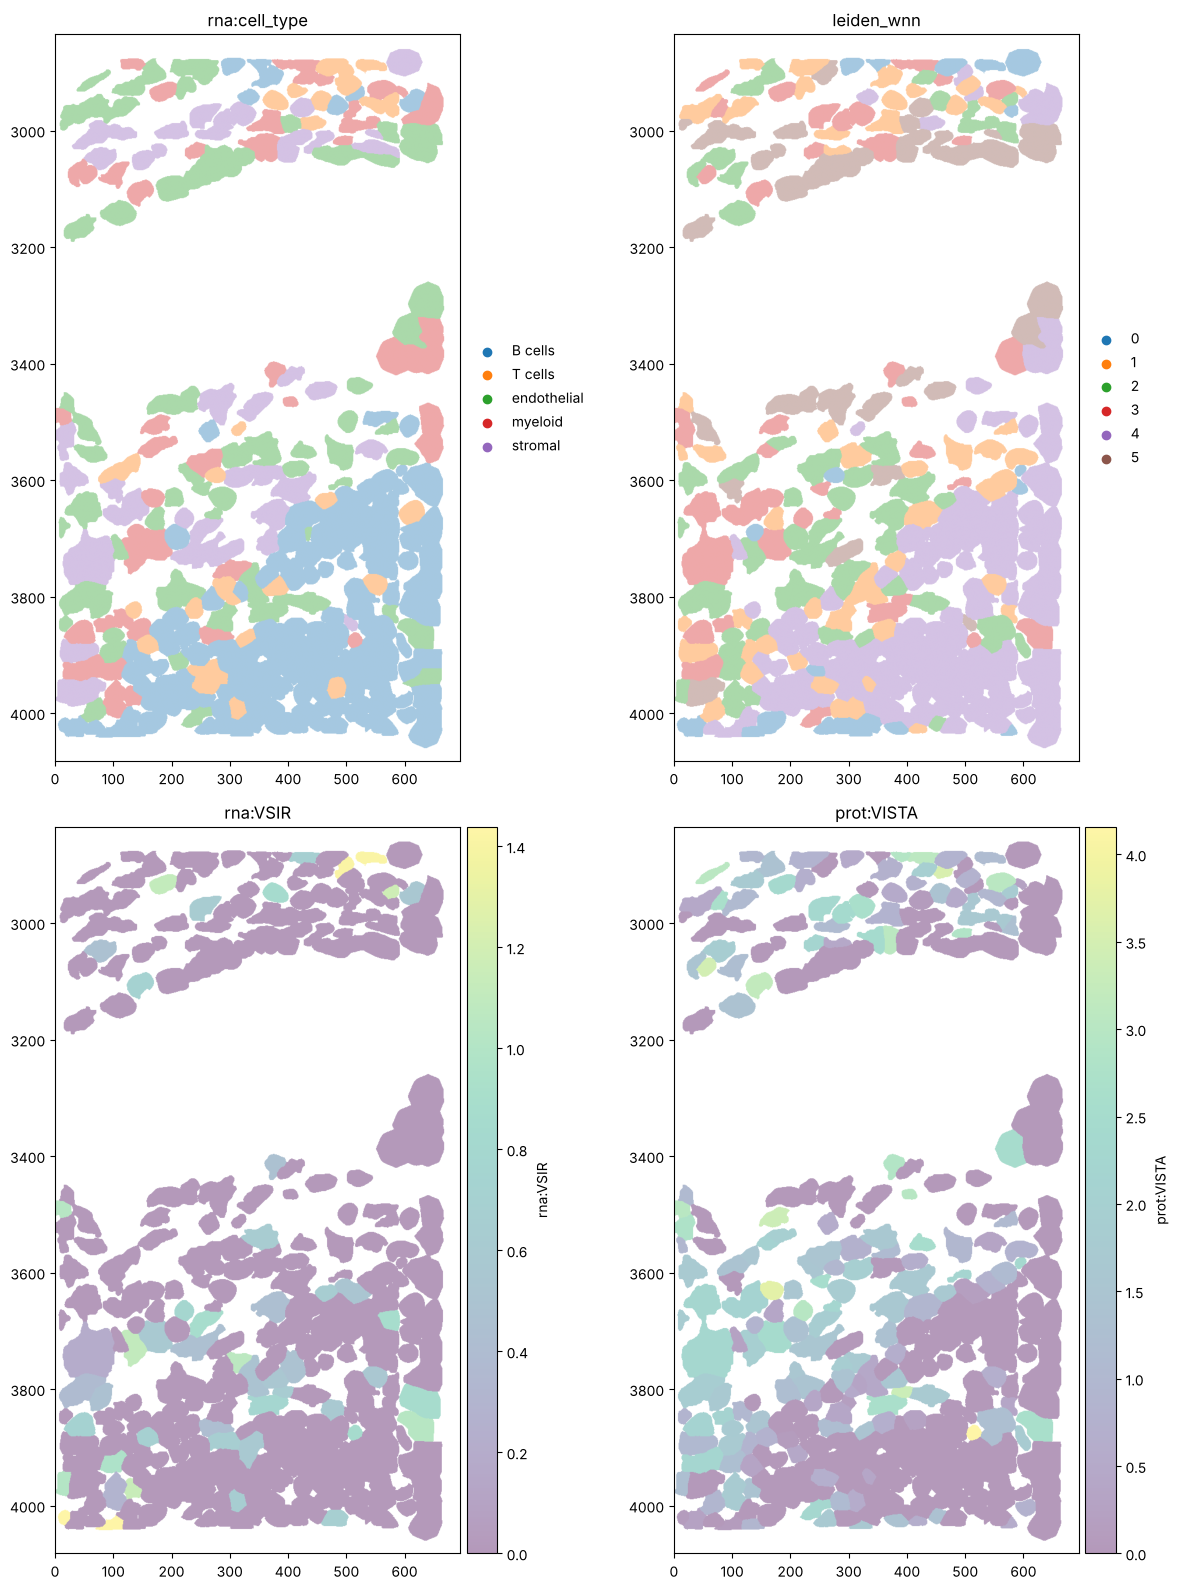

In [20]:
fig, axs = plt.subplots(2, 2, figsize=(12, 16))
colors = ["rna:cell_type", "leiden_wnn", "rna:VSIR", "prot:VISTA"]
for ax, color in zip(axs.flat, colors, strict=True):
    tissue.pl.render_labels("cell_labels", color=color, table_name="table").pl.show(ax=ax, title=color)
plt.tight_layout()

Zooming in, the protein stain behind the quantification is shown with the outlines of the cells, colored by the
VISTA intensity measured in each of them.

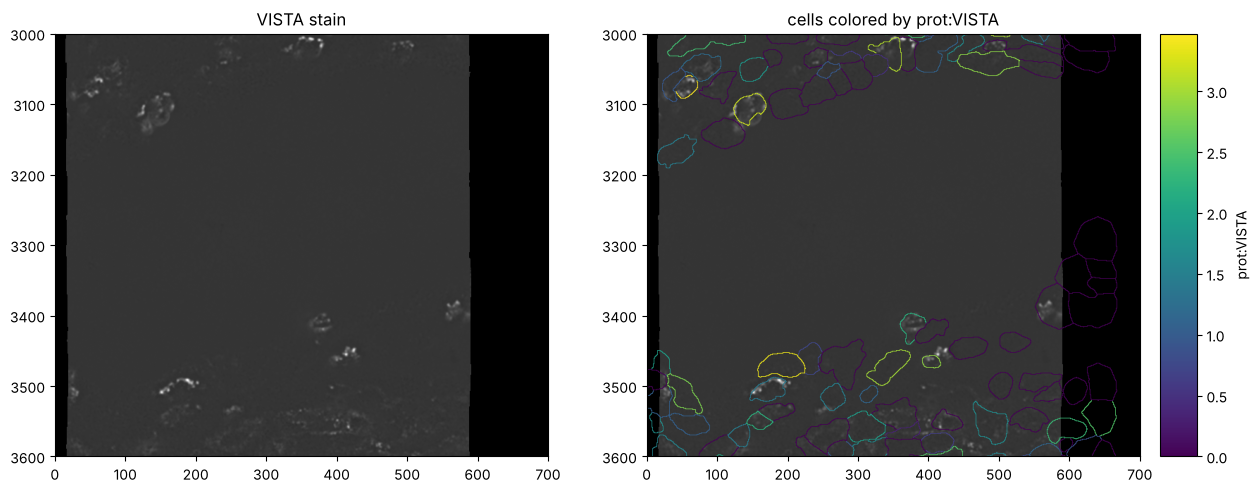

In [21]:
zoom = sdata.query.bounding_box(
    axes=("x", "y"),
    min_coordinate=[0, 3000],
    max_coordinate=[700, 3600],
    target_coordinate_system="global",
)
fig, axs = plt.subplots(1, 2, figsize=(14, 6))
zoom.pl.render_images("morphology_focus", channel="VISTA", cmap="gray", colorbar=False).pl.show(
    ax=axs[0], title="VISTA stain"
)
zoom.pl.render_images("morphology_focus", channel="VISTA", cmap="gray", colorbar=False).pl.render_labels(
    "cell_labels",
    color="prot:VISTA",
    table_name="table",
    fill_alpha=0,
    outline_alpha=1,
    contour_px=3,
).pl.show(ax=axs[1], title="cells colored by prot:VISTA")

## 10. Save and reload

The MuData table is written in the MuData zarr layout inside the SpatialData store, so it can also be opened directly
with `mudata` (and each modality with `anndata`).

In [22]:
path = Path("xenium_gene_protein.zarr")
sdata.write(path, overwrite=True)
sdata_read = sd.read_zarr(path)
table = sdata_read["table"]
print(type(table).__name__, table.shape, list(table.mod))
print(
    "modality layers kept:",
    list(table.mod["rna"].layers),
    list(table.mod["prot"].layers),
)

MuData (334, 409) ['rna', 'prot']
modality layers kept: ['counts', None] ['intensity', None]


In [23]:
md.read_zarr(path / "tables" / "table")

MuData object with n_obs × n_vars = 334 × 409
  obs:	'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'rna%3Amod_weight', 'prot%3Amod_weight', 'leiden_wnn'
  uns:	'leiden_wnn', 'spatialdata_attrs', 'umap', 'wnn'
  obsm:	'spatial', 'X_umap'
  obsp:	'wnn_distances', 'wnn_connectivities'
  2 modalities
    rna:	334 × 405
      obs:	'leiden', 'cell_type'
      var:	'gene_ids', 'feature_types', 'genome'
      uns:	'pca', 'log1p', 'umap', 'leiden', 'neighbors', 'rank_genes_groups'
      obsm:	'X_umap', 'X_pca'
      varm:	'PCs'
      layers:	'counts', None
      obsp:	'distances', 'connectivities'
    prot:	334 × 4
      var:	'gene_ids', 'feature_types', 'genome'
      uns:	'neighbors'
      layers:	'intensity', None
      obsp:	'connectivities', 'distanc